## IIR Filter Design for the refractive phase spectrum

The code below calls the MATLAB PSD helper with external spectral parameters and `rho_F / v_eff`, then loads the bins as NumPy arrays.

In [ ]:
from pathlib import Path
import os
import subprocess

import numpy as np
from scipy.io import loadmat


project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
matlab_cmd = os.environ.get("MATLAB_CMD", "matlab")
output_file = project_root / "data" / "interim" / "refractive_phase_psd.mat"
rhof_veff_ratio = 1
U = 2
p1 = 2.2
p2 = 3.8
mu0 = 1
sim_time = 300
t_samp = 0.02


def q(value):
    return "'" + str(value).replace("'", "''") + "'"


matlab_code = f"""
addpath({q(project_root / 'tools' / 'cpssm_utils')});
get_refractive_phase_psd( ...
    'output_file', {q(output_file)}, ...
    'rhof_veff_ratio', {rhof_veff_ratio}, ...
    'U', {U}, ...
    'p1', {p1}, ...
    'p2', {p2}, ...
    'mu0', {mu0}, ...
    'sim_time', {sim_time}, ...
    't_samp', {t_samp});
"""

subprocess.run(
    [matlab_cmd, "-batch", matlab_code],
    cwd=project_root,
    check=True,
)

mat = loadmat(output_file, squeeze_me=True)
frequency_hz = np.ravel(mat["frequency_hz"]).astype(float)
omega_rad_sample = np.ravel(mat["omega_rad_sample"]).astype(float)
mu = np.ravel(mat["mu"]).astype(float)
P_mu = np.ravel(mat["P_mu"]).astype(float)
S_phi_hz = np.ravel(mat["S_phi_hz"]).astype(float)
sample_rate_hz = float(np.asarray(mat["sample_rate_hz"]).squeeze())

target_mag = np.sqrt(np.maximum(S_phi_hz, 0.0) * sample_rate_hz)
frequency_hz.shape, S_phi_hz.shape, sample_rate_hz

> In path (line 109)
In addpath (line 96) 


((7679,), (7679,), 50.0)

Fitting an IIR filter into the phase PSD

(array([ 4.47468688e-03, -1.20822741e-03, -2.51150478e-03, -1.83926591e-04,
         8.53476359e-05]),
 array([ 1.        , -2.50118507,  1.68070526,  0.14463435, -0.32415396]),
 np.int64(0),
 np.float64(12.464245509472168),
 np.float64(0.1659667148856642),
 np.float64(0.9997637605729361),
 np.float64(0.9106570567355536))

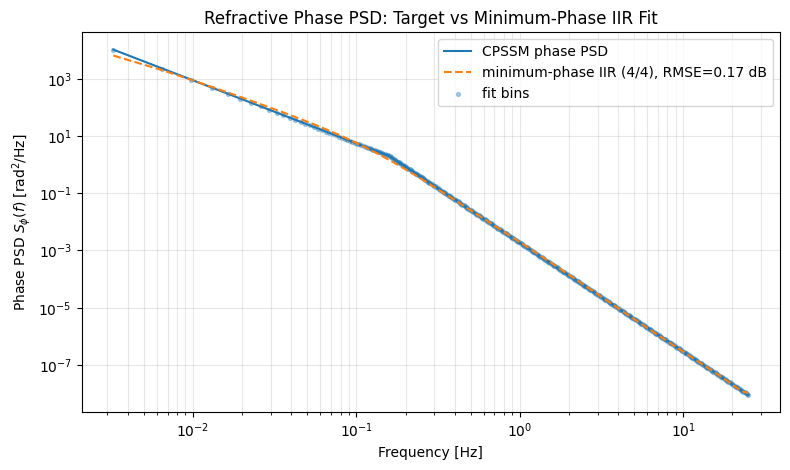

In [ ]:
import matplotlib.pyplot as plt
from PyDynamic.model_estimation.fit_filter import LSIIR
from scipy.signal import freqz, hilbert


Nb = 4
Na = 4
fit_bins = 512

log_idx = np.round(np.geomspace(1, frequency_hz.size - 1, fit_bins - 1)).astype(int)
fit_idx = np.unique(np.concatenate(([0], log_idx)))


def minimum_phase_response_from_magnitude(magnitude):
    magnitude_floor = np.maximum(magnitude, np.finfo(float).tiny)

    # Add approximate DC and Nyquist endpoints because the exported PSD has only
    # strictly positive frequencies between 0 and Fs/2.
    magnitude_half = np.concatenate((
        [magnitude_floor[0]],
        magnitude_floor,
        [magnitude_floor[-1]],
    ))

    # Mirror the half-spectrum to represent one full frequency turn around the
    # unit circle: [DC ... Nyquist ... DC].
    log_magnitude_half = np.log(magnitude_half)
    log_magnitude_full = np.concatenate((
        log_magnitude_half,
        log_magnitude_half[-2:0:-1],
    ))

    # For a minimum-phase filter, the phase is determined by the Hilbert transform
    # of log magnitude. This gives LSIIR a complex target, not only a magnitude.
    # This invokes causality and stability of the phase PSD.
    # SEE: Equation 12.54 of Oppenheim & Schafer, 3rd edition, 2010.
    phase_full = -np.imag(hilbert(log_magnitude_full))
    # SEE: Equation 12.53 of Oppenheim & Schafer, 3rd edition, 2010.
    response_full = np.exp(log_magnitude_full + 1j * phase_full)

    # Drop the synthetic DC and Nyquist endpoints so the result lines up with
    # frequency_hz and target_mag.
    return response_full[1 : magnitude.size + 1]


H_target = minimum_phase_response_from_magnitude(target_mag)

b_iir, a_iir, tau_iir, Uab_iir, rms_iir = LSIIR(
    H_target[fit_idx],
    Nb,
    Na,
    frequency_hz[fit_idx],
    sample_rate_hz,
    tau=0,
    verbose=False,
    return_rms=True,
)

_, H_iir = freqz(b_iir, a_iir, worN=omega_rad_sample)
S_phi_iir_hz = np.maximum(np.abs(H_iir) ** 2 / sample_rate_hz, np.finfo(float).tiny)
fit_rmse_db = np.sqrt(
    np.mean((10 * np.log10(S_phi_iir_hz) - 10 * np.log10(S_phi_hz)) ** 2)
)
max_pole_radius = np.max(np.abs(np.roots(a_iir)))
max_zero_radius = np.max(np.abs(np.roots(b_iir)))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.loglog(frequency_hz, S_phi_hz, label="CPSSM phase PSD")
ax.loglog(
    frequency_hz,
    S_phi_iir_hz,
    "--",
    label=f"minimum-phase IIR ({Nb}/{Na}), RMSE={fit_rmse_db:.2f} dB",
)
ax.scatter(
    frequency_hz[fit_idx],
    S_phi_hz[fit_idx],
    s=8,
    alpha=0.35,
    label="fit bins",
)
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel(r"Phase PSD $S_\phi(f)$ [rad$^2$/Hz]")
ax.set_title("Refractive Phase PSD: Target vs Minimum-Phase IIR Fit")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()

b_iir, a_iir, tau_iir, rms_iir, fit_rmse_db, max_pole_radius, max_zero_radius
